In [18]:
#Jay Schroeder
#Oct 11th, 2026
#Homework 7

In [29]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import curve_fit

Problem 3


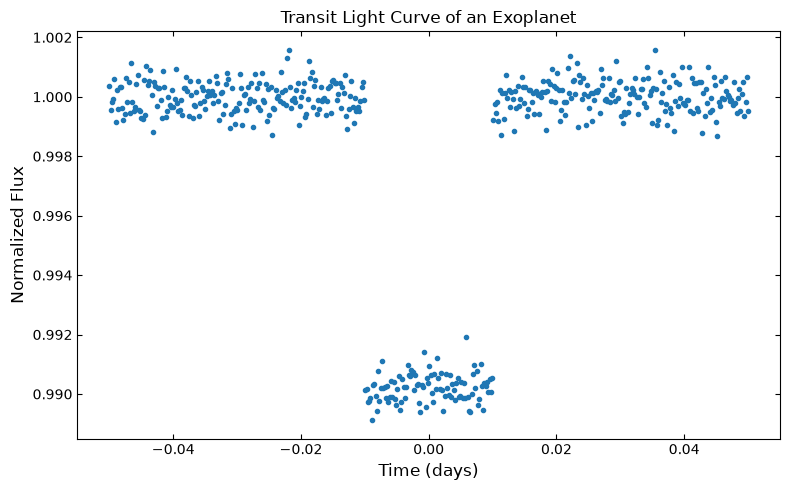

In [16]:
print( 'Problem 3' )

#reads the transit data provided
data = pd.read_csv( 'hw7_synthetic_transit_lightcurve.csv' )

#defining the columns of the data
time = data['Time (days)']
flux = data['Normalized Flux']

#building the plot and formating to make it publication ready
fig, ax = plt.subplots( figsize=(8,5) )

ax.scatter( time, flux, marker='.' )
ax.set_xlabel( 'Time (days)', fontsize=12 )
ax.set_ylabel( 'Normalized Flux', fontsize=12 )
ax.set_title( 'Transit Light Curve of an Exoplanet', fontsize=12 )
ax.tick_params( direction='in', top=True, right=True )

fig.tight_layout()
plt.show()

In [72]:
#function for the box window of this graph
def box_function( x, center, width, height ):
    ''' A function which returns a rectangular window function for 
        exoplanet transit data.

    Parameters
    ----------
    x : array_like 
        Variable which takes in an array of observational times.
        
    center : float 
        The time at the center of the rectangular window.

    width : float 
        The total width of the rectangular window.

    height : float
        The value ascribed to the height of the window within set boundaries.

    Returns
    -------
    window : numpy.ndarray
        An array containing the rectangular window function. Values beyond 
        the window are attributed to zero, while values inside the window 
        are set equal to a specified height. 

    Example
    -------
    >>> box_function( np.array([0, 1, 2, 3, 4]), 2.0, 2.0, -0.01 )
    array( [0.0, -0.01, -0.01, -0.01, 0.0] )

    Updates
    -------
    '''

    x = np.asarray(x)
    window = np.zeros(x.shape)
    window[ np.abs(x - center) <= width / 2 ] = height

    return window

Initial guesses: [np.float64(0.0), np.float64(0.0198396793587174), np.float64(-0.010880180597369615)]
Transit depth: 0.010880180597369615


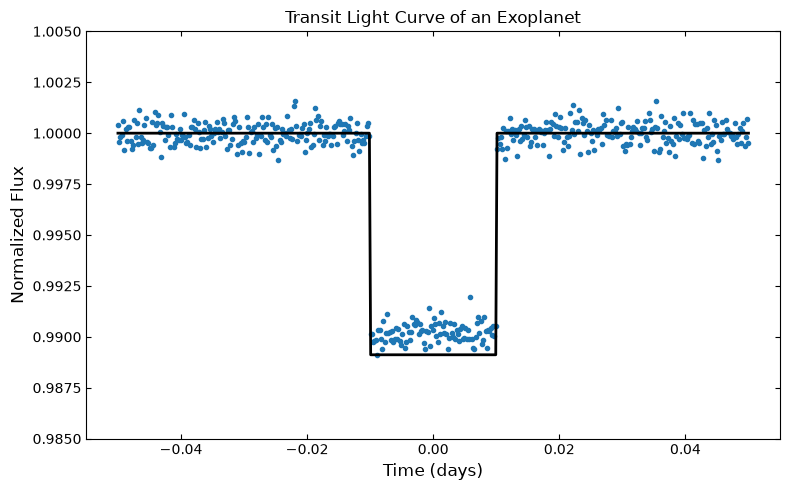

Center: 0.0
Width: 0.0198396793587174
Height: -0.010880180597369615
Fitted parameters: [ 0.          0.01983968 -0.01088018]
Box model range: -0.010880180597369615 0.0


In [74]:
#initial guess of transit parameters
center_guess = (time[in_transit].min() + time[in_transit].max()) / 2
height_guess = flux.min() - 1
width_guess = time[in_transit].max() - time[in_transit].min()
p0 = [center_guess, width_guess, height_guess]

print('Initial guesses:', p0)

#fitting the box function to the data and extracting the best-fit parameter
popt, pcov = curve_fit( box_function, time, flux - 1, p0=p0, bounds=( [-0.05, 0.005, -0.011], [0.01, 0.04, 0.0] ) )
center_fit, width_fit, height_fit = popt

#calculating the planet's radius and fitting tis to the model
fig, ax = plt.subplots( figsize=(8,5) )

model = 1 + box_function(time, *popt)

ax.scatter( time, flux, marker='.' )
ax.plot( time, model, color='black', linewidth=2, label='Best-fit box model' )

ax.set_xlabel( 'Time (days)', fontsize=12 )
ax.set_ylabel( 'Normalized Flux', fontsize=12 )
ax.set_title( 'Transit Light Curve of an Exoplanet', fontsize=12 )
ax.tick_params( direction='in', top=True, right=True )
ax.set_ylim(0.985, 1.005)

fig.tight_layout()
plt.show()

print('Center:', center_fit)
print('Width:', width_fit)
print('Height:', height_fit)
print('Fitted parameters:', popt)
print('Box model range:',
      box_function(time, *popt).min(),
      box_function(time, *popt).max())

In [ ]:
#Problem 3, part bii
''' This fit is hard to believe since the lower bounds do not actually lie within 
    the data. Since the rectangular window function is discontinuous, curve_fit()
    not be the right right approach given the center and width. I could try a
    different initial guess or use an alternative fitting approach to check the
    parameters.'''